# Exploración de biodiversidad ibérica (ES y PT) con la API pública de GBIF

En este cuaderno consultamos la API pública de **GBIF** (*Global Biodiversity Information Facility*) para explorar el catálogo de especies registradas en **España (`ES`) y Portugal (`PT`)**, analizar su denominación científica y común, ver dónde se han observado y descargar, validar y cartografiar registros de presencia de la especie seleccionada (por defecto, *Canis lupus*).

## Objetivo y alcance

El flujo de trabajo se divide en dos fases:

1. **Exploración del catálogo taxonómico en ES y PT:** consulta agregada mediante facetas (`facet=speciesKey`) y metadatos de `/v1/species/{speciesKey}` para listar alfabéticamente las especies presentes en la Península Ibérica, su nombre común en español/portugués y las principales zonas donde se han observado.
2. **Análisis detallado de la especie seleccionada (`ESPECIE_OBJETIVO`):** diagnóstico progresivo de filtros, descarga paginada, normalización Darwin Core, estadísticas territoriales/altitudinales, exportación CSV y mapa interactivo con Folium.

**Filtros aplicados al análisis de ocurrencias:**
- **Taxonomía (`taxonKey`):** resuelto dinámicamente mediante `/v1/species/match`.
- **Países (`country`):** `["ES", "PT"]` (España y Portugal).
- **Periodo (`year`):** `2020,2026`, tanto para el catálogo como para la descarga detallada, igual que en el cuaderno v7.
- **Calidad espacial:** registros con coordenadas (`hasCoordinate=True`) y sin incidencias geoespaciales (`hasGeospatialIssue=False`).

**Importante:** los recuentos representan registros publicados en GBIF, no la población total ni el número de individuos únicos.

## 0. Preparación del entorno

Se recomienda Python 3.14 y un entorno virtual independiente.

### Opción A: `uv`

```bash
uv venv --python 3.14 .venv

# Windows PowerShell
.venv\\Scripts\\Activate.ps1

# Linux/macOS
# source .venv/bin/activate

uv pip install requests pandas folium matplotlib seaborn ipykernel
python -m ipykernel install --user --name=gbif-py314 --display-name="Python 3.14 (GBIF)"
```

### Opción B: `venv` estándar

```bash
python -m venv .venv

# Windows PowerShell
.venv\\Scripts\\Activate.ps1

# Linux/macOS
# source .venv/bin/activate

python -m pip install --upgrade pip
python -m pip install requests pandas folium matplotlib seaborn ipykernel
python -m ipykernel install --user --name=gbif-py314 --display-name="Python 3.14 (GBIF)"
```

Selecciona después el kernel **Python 3.14 (GBIF)** en Jupyter o VS Code. Si instalas paquetes desde una celda, usa `%pip install seaborn` para instalarlos en el entorno del kernel activo.

In [19]:
import html
import sys
import time
from typing import Any

import folium
from folium.plugins import MarkerCluster
import matplotlib.pyplot as plt
import pandas as pd
import requests

print(f"Intérprete activo: Python {sys.version.split()[0]}")
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 1200)

# Sesión HTTP reutilizable. El timeout evita esperas indefinidas.
GBIF_API = "https://api.gbif.org/v1"
session = requests.Session()
session.headers.update({
    "User-Agent": "GBIF-Biodiversity-Explorer/2.0 (educational notebook)"
})

Intérprete activo: Python 3.14.3


## 1. Análisis de la API de especies en ES y PT (catálogo alfabético, denominación y zonas)

La API de GBIF permite combinar tres *endpoints* para descubrir qué especies hay registradas en España (`ES`) y Portugal (`PT`) sin necesidad de descargar millones de registros individuales:

- **`/v1/occurrence/search` con `facet=speciesKey`:** devuelve el número de especies distintas en la muestra y el recuento de observaciones de cada una en `ES` y `PT`.
- **`/v1/species/{speciesKey}` y `/v1/species/{speciesKey}/vernacularNames`:** obtiene la denominación científica oficial del *GBIF Backbone Taxonomy* y los nombres comunes registrados (`spa` / `por`).
- **`/v1/occurrence/search` con `facet=country` y `facet=stateProvince`:** identifica en qué país y provincias/distritos se concentra cada especie.

El listado resultante se ordena **alfabéticamente por nombre científico** para que puedas elegir cualquier especie y probarla en las celdas siguientes modificando `ESPECIE_OBJETIVO`.

In [20]:
# 1.1 Funciones de consulta y catálogo de especies disponibles en ES y PT
import pandas as pd

def obtener_denominacion_especie(species_key: int) -> dict[str, Any]:
    """Recupera nombre científico, denominación oficial y nombre común (ES/PT)."""
    resp_sp = session.get(f"{GBIF_API}/species/{species_key}", timeout=20)
    resp_sp.raise_for_status()
    info = resp_sp.json()

    nombre_cientifico = info.get("canonicalName") or info.get("scientificName") or f"speciesKey:{species_key}"
    denominacion_oficial = info.get("scientificName", nombre_cientifico)
    reino = info.get("kingdom", "Desconocido")

    resp_vern = session.get(f"{GBIF_API}/species/{species_key}/vernacularNames", timeout=20)
    denominacion_comun = "Sin denominación común registrada"
    if resp_vern.ok:
        resultados_vern = resp_vern.json().get("results", [])
        nombres_es = list(dict.fromkeys(
            v["vernacularName"].strip()
            for v in resultados_vern
            if v.get("language") == "spa" and v.get("vernacularName")
        ))
        nombres_pt = list(dict.fromkeys(
            v["vernacularName"].strip()
            for v in resultados_vern
            if v.get("language") == "por" and v.get("vernacularName")
        ))

        partes = []
        if nombres_es:
            partes.append(f"ES: {', '.join(nombres_es[:2])}")
        if nombres_pt:
            partes.append(f"PT: {', '.join(nombres_pt[:2])}")

        if partes:
            denominacion_comun = " | ".join(partes)
        elif resultados_vern:
            primero = next((v.get("vernacularName") for v in resultados_vern if v.get("vernacularName")), None)
            if primero:
                idioma = resultados_vern[0].get("language", "otro")
                denominacion_comun = f"{primero.strip()} ({idioma})"

    return {
        "speciesKey": species_key,
        "nombre_cientifico": nombre_cientifico,
        "denominacion_oficial": denominacion_oficial,
        "denominacion_comun": denominacion_comun,
        "reino": reino,
    }

def obtener_donde_se_observa(
    species_key: int,
    paises: list[str],
    periodo: str,
    top_territorios: int = 4,
) -> tuple[str, str]:
    """Devuelve el reparto por país (ES vs PT) y las principales provincias/distritos."""
    params = {
        "speciesKey": species_key,
        "country": paises,
        "year": periodo,
        "hasCoordinate": True,
        "hasGeospatialIssue": False,
        "limit": 0,
        "facet": ["country", "stateProvince"],
        "facetLimit": top_territorios,
    }
    resp = session.get(f"{GBIF_API}/occurrence/search", params=params, timeout=20)
    if not resp.ok:
        return "No disponible", "No disponible"

    facetas = {f["field"]: f.get("counts", []) for f in resp.json().get("facets", [])}

    reparto_paises = ", ".join(
        f"{c["name"]}: {c["count"]:,}" for c in facetas.get("COUNTRY", [])
    ) or "Sin datos"

    principales_zonas = ", ".join(
        f"{c["name"]} ({c["count"]:,})" for c in facetas.get("STATE_PROVINCE", [])
    ) or "Sin territorio especificado"

    return reparto_paises, principales_zonas

def explorar_especies_ibericas(
    paises: list[str] = ["ES", "PT"],
    periodo: str = "2020,2026",
    reino_key: int | None = 1,
    taxon_padre_key: int | None = None,
    limite_especies: int = 25,
) -> pd.DataFrame:
    """Consulta en GBIF las especies presentes en ES y PT y las ordena alfabéticamente."""
    params: dict[str, Any] = {
        "country": paises,
        "year": periodo,
        "hasCoordinate": True,
        "hasGeospatialIssue": False,
        "limit": 0,
        "facet": "speciesKey",
        "facetLimit": limite_especies,
    }
    if reino_key is not None:
        params["kingdomKey"] = reino_key
    if taxon_padre_key is not None:
        params["taxonKey"] = taxon_padre_key

    resp = session.get(f"{GBIF_API}/occurrence/search", params=params, timeout=30)
    resp.raise_for_status()
    payload = resp.json()

    total_ocurrencias = payload.get("count", 0)
    facetas = payload.get("facets", [])
    conteos_especies = facetas[0].get("counts", []) if facetas else []

    print(f"Ámbito consultado: {', '.join(paises)} | Periodo: {periodo}")
    print(f"Total de ocurrencias georreferenciadas que cumplen los filtros: {total_ocurrencias:,}")
    print(f"Especies recuperadas en el top de facetas: {len(conteos_especies)} (ordenando alfabéticamente...")

    filas: list[dict[str, Any]] = []
    for item in conteos_especies:
        sp_key = int(item["name"])
        total_obs = int(item["count"])
        meta = obtener_denominacion_especie(sp_key)
        reparto_pais, zonas = obtener_donde_se_observa(sp_key, paises, periodo)
        meta["observaciones_es_pt"] = total_obs
        meta["reparto_por_pais"] = reparto_pais
        meta["donde_se_observa_top"] = zonas
        filas.append(meta)

    df_esp = pd.DataFrame(filas)
    if not df_esp.empty:
        df_esp = df_esp.sort_values("nombre_cientifico", key=lambda s: s.str.lower()).reset_index(drop=True)
    return df_esp

# Ejecutar catálogo inicial para conocer las opciones
df_catalogo_especies = explorar_especies_ibericas(limite_especies=25)
display(df_catalogo_especies[["nombre_cientifico", "denominacion_comun", "observaciones_es_pt", "reparto_por_pais"]])

Ámbito consultado: ES, PT | Periodo: 2020,2026
Total de ocurrencias georreferenciadas que cumplen los filtros: 42,122,155
Especies recuperadas en el top de facetas: 25 (ordenando alfabéticamente...


,nombre_cientifico,denominacion_comun,observaciones_es_pt,reparto_por_pais
0,Anas platyrhynchos,ES: Anade Azulón,570817,"ES: 471,063, PT: 99,754"
1,Ardea cinerea,Agró Blau (cat),441483,"ES: 347,381, PT: 94,150"
2,Carduelis carduelis,"ES: Cardelino, Colorin",716940,"ES: 573,276, PT: 143,664"
3,Chloris chloris,Common Greenfinch (eng),529047,"ES: 389,679, PT: 139,368"
4,Columba livia,Bjargdúfa (isl),594867,"ES: 426,313, PT: 168,583"
5,Columba palumbus,Agɔnxwelé (),776356,"ES: 655,114, PT: 121,242"
6,Curruca melanocephala,ES: Curruca cabecinegra,553969,"ES: 401,048, PT: 152,921"
7,Cyanistes caeruleus,(Ευρωπαϊκή) Γαλαζοπαπαδίτσα (ell),430632,"ES: 331,240, PT: 99,392"
8,Erithacus rubecula,Boc'hruz (bre),713941,"ES: 550,405, PT: 163,536"
9,Falco tinnunculus,"ES: Cernicalo común, Cernícalo Vulgar",429054,"ES: 358,545, PT: 70,509"


In [21]:
# Analizar si existen especies en el catálogo con 0 valores nulos en todas sus columnas
if 'df_catalogo_especies' in globals() and not df_catalogo_especies.empty:
    # Evaluamos qué filas no contienen ningún valor nulo (NaN o None)
    filas_completas = df_catalogo_especies[df_catalogo_especies.notna().all(axis=1)]

    print(f"Especies analizadas en el catálogo: {len(df_catalogo_especies)}")
    print(f"Especies con datos en absolutamente todas las columnas: {len(filas_completas)}\n")

    if len(filas_completas) == len(df_catalogo_especies):
        print("Todas las especies están en la tabla del catálogo mostrada anteriormente.")
    elif not filas_completas.empty:
        display(filas_completas[["nombre_cientifico", "denominacion_comun", "observaciones_es_pt", "reparto_por_pais"]])
    else:
        print("No hay ninguna especie que tenga el 100% de los campos llenos (generalmente debido a campos vacíos en 'denominacion_comun' para ciertas especies menos conocidas o con dialectos no registrados).")
        # Mostramos el conteo de nulos por columna para entender dónde se pierde la información
        print("\nCantidad de valores ausentes por columna en el catálogo de especies:")
        display(df_catalogo_especies.isna().sum().rename("valores_ausentes").to_frame())
else:
    print("El DataFrame df_catalogo_especies no está disponible. Por favor, asegúrate de haber ejecutado la celda del catálogo (1.1).")

Especies analizadas en el catálogo: 25
Especies con datos en absolutamente todas las columnas: 25

Todas las especies están en la tabla del catálogo mostrada anteriormente.


In [22]:
# Evaluar qué columnas del estándar Darwin Core en la descarga detallada (df) tienen datos completos (0% nulos)
if 'df' in globals() and not df.empty:
    total_registros = len(df)
    conteo_no_nulos = df.notna().sum().to_frame(name="registros_con_datos")
    conteo_no_nulos["porcentaje_completitud"] = (conteo_no_nulos["registros_con_datos"] / total_registros) * 100

    print(f"=== Análisis de completitud de columnas en df ({ESPECIE_OBJETIVO}) ===")
    print(f"Total de ocurrencias analizadas: {total_registros}\n")

    # Separar columnas totalmente completas de las que tienen datos ausentes
    columnas_completas = conteo_no_nulos[conteo_no_nulos["porcentaje_completitud"] == 100]
    columnas_incompletas = conteo_no_nulos[conteo_no_nulos["porcentaje_completitud"] < 100]

    print("✔ Columnas 100% COMPLETAS (sin ningún valor nulo):")
    display(columnas_completas)

    if not columnas_incompletas.empty:
        print("\n⚠ Columnas INCOMPLETAS (con valores nulos/ausentes):")
        display(columnas_incompletas.sort_values(by="porcentaje_completitud", ascending=False))
else:
    print("El DataFrame de registros detallados 'df' no está disponible. Ejecuta las celdas de la sección 3.")

=== Análisis de completitud de columnas en df (Canis Lupus) ===
Total de ocurrencias analizadas: 36

✔ Columnas 100% COMPLETAS (sin ningún valor nulo):


,registros_con_datos,porcentaje_completitud
key,36,100.0
scientificName,36,100.0
countryCode,36,100.0
decimalLatitude,36,100.0
decimalLongitude,36,100.0
basisOfRecord,36,100.0
stateProvince,36,100.0
institutionCode,36,100.0



⚠ Columnas INCOMPLETAS (con valores nulos/ausentes):


,registros_con_datos,porcentaje_completitud
eventDate,21,58.333333
year,21,58.333333
month,21,58.333333
eventDateParsed,21,58.333333
elevation,0,0.000000


### 1.2 Configuración de la especie objetivo a analizar

Una vez revisado el catálogo anterior, define la especie objetivo que deseas estudiar en profundidad en la siguiente celda. Los nombres binomiales simples se normalizan (por ejemplo, `Canis Lupus` a `Canis lupus`) y se comprueba que GBIF devuelva el mismo nombre canónico. Para nombres con autor u otros formatos, revisa el taxón resuelto antes de continuar.

In [23]:
PAISES_OBJETIVO = ["ES", "PT"]
PERIODO_OBJETIVO = "2020,2026"
ESPECIE_OBJETIVO = "Canis lupus"  # <-- Elige aquí cualquiera de las especies de la tabla anterior

In [24]:
def obtener_denominacion_especie(species_key: int) -> dict[str, Any]:
    """Recupera nombre científico, denominación oficial y nombre común (ES/PT)."""
    resp_sp = session.get(f"{GBIF_API}/species/{species_key}", timeout=20)
    resp_sp.raise_for_status()
    info = resp_sp.json()

    nombre_cientifico = info.get("canonicalName") or info.get("scientificName") or f"speciesKey:{species_key}"
    denominacion_oficial = info.get("scientificName", nombre_cientifico)
    reino = info.get("kingdom", "Desconocido")

    resp_vern = session.get(f"{GBIF_API}/species/{species_key}/vernacularNames", timeout=20)
    denominacion_comun = "Sin denominación común registrada"
    if resp_vern.ok:
        resultados_vern = resp_vern.json().get("results", [])
        nombres_es = list(dict.fromkeys(
            v["vernacularName"].strip()
            for v in resultados_vern
            if v.get("language") == "spa" and v.get("vernacularName")
        ))
        nombres_pt = list(dict.fromkeys(
            v["vernacularName"].strip()
            for v in resultados_vern
            if v.get("language") == "por" and v.get("vernacularName")
        ))

        partes = []
        if nombres_es:
            partes.append(f"ES: {', '.join(nombres_es[:2])}")
        if nombres_pt:
            partes.append(f"PT: {', '.join(nombres_pt[:2])}")

        if partes:
            denominacion_comun = " | ".join(partes)
        elif resultados_vern:
            primero = next((v.get("vernacularName") for v in resultados_vern if v.get("vernacularName")), None)
            if primero:
                idioma = resultados_vern[0].get("language", "otro")
                denominacion_comun = f"{primero.strip()} ({idioma})"

    return {
        "speciesKey": species_key,
        "nombre_cientifico": nombre_cientifico,
        "denominacion_oficial": denominacion_oficial,
        "denominacion_comun": denominacion_comun,
        "reino": reino,
    }

def obtener_donde_se_observa(
    species_key: int,
    paises: list[str],
    periodo: str,
    top_territorios: int = 4,
) -> tuple[str, str]:
    """Devuelve el reparto por país (ES vs PT) y las principales provincias/distritos."""
    params = {
        "speciesKey": species_key,
        "country": paises,
        "year": periodo,
        "hasCoordinate": True,
        "hasGeospatialIssue": False,
        "limit": 0,
        "facet": ["country", "stateProvince"],
        "facetLimit": top_territorios,
    }
    resp = session.get(f"{GBIF_API}/occurrence/search", params=params, timeout=20)
    if not resp.ok:
        return "No disponible", "No disponible"

    facetas = {f["field"]: f.get("counts", []) for f in resp.json().get("facets", [])}

    reparto_paises = ", ".join(
        f"{c["name"]}: {c["count"]:,}" for c in facetas.get("COUNTRY", [])
    ) or "Sin datos"

    principales_zonas = ", ".join(
        f"{c["name"]} ({c["count"]:,})" for c in facetas.get("STATE_PROVINCE", [])
    ) or "Sin territorio especificado"

    return reparto_paises, principales_zonas

### Selección de la especie para el análisis detallado

La siguiente celda resuelve el `taxonKey` de `ESPECIE_OBJETIVO` (por defecto `Canis lupus`) mediante `/v1/species/match` para ejecutar todo el flujo posterior en **ES y PT**.

In [25]:
def obtener_taxon_key(
    nombre_cientifico: str,
    reino: str = "Animalia",
) -> tuple[int, str]:
    """Resuelve un nombre en GBIF y exige una coincidencia taxonómica exacta."""
    partes = nombre_cientifico.split()
    es_binomial = len(partes) == 2 and all(parte.isalpha() for parte in partes)
    nombre_consulta = (
        f"{partes[0].capitalize()} {partes[1].lower()}"
        if es_binomial else nombre_cientifico.strip()
    )
    if nombre_consulta != nombre_cientifico:
        print(f"Nombre consultado en GBIF: {nombre_consulta!r} (entrada: {nombre_cientifico!r})")
    url = f"{GBIF_API}/species/match"
    respuesta = session.get(
        url,
        params={"name": nombre_consulta, "kingdom": reino, "strict": True},
        timeout=20,
    )
    respuesta.raise_for_status()
    datos: dict[str, Any] = respuesta.json()

    usage_key = datos.get("usageKey")
    nombre_oficial = datos.get("scientificName")
    tipo_coincidencia = datos.get("matchType")

    if usage_key is None or not nombre_oficial:
        raise ValueError(
            f"GBIF no ha encontrado un taxón para {nombre_cientifico!r}. "
            f"Respuesta: {datos}"
        )

    if tipo_coincidencia != "EXACT":
        raise ValueError(
            f"La coincidencia para {nombre_cientifico!r} no es exacta "
            f"(matchType={tipo_coincidencia!r}). Revisa el nombre antes de continuar."
        )

    nombre_canonico = datos.get("canonicalName")
    if es_binomial and (not nombre_canonico or nombre_canonico.casefold() != nombre_consulta.casefold()):
        raise ValueError(
            f"GBIF devolvió el nombre canónico {nombre_canonico!r} para {nombre_consulta!r}. "
            "Revisa el nombre científico antes de continuar."
        )

    return int(usage_key), str(nombre_oficial)


taxon_key, nombre_oficial = obtener_taxon_key(ESPECIE_OBJETIVO)
print(f"Taxón activo: {nombre_oficial} -> taxonKey={taxon_key} | Países: {PAISES_OBJETIVO}")

Taxón activo: Canis lupus Linnaeus, 1758 -> taxonKey=5219173 | Países: ['ES', 'PT']


## 2. Consulta multicriterio en ES y PT con bucle de paginación (`offset` y `limit`)

La API de ocurrencias de GBIF (`/v1/occurrence/search`) admite múltiples valores para el parámetro `country` (en `requests`, pasando una lista como `country=["ES", "PT"]`).

En esta sección ejecutamos primero un diagnóstico progresivo por filtros y descargamos después hasta `MAX_REGISTROS` ocurrencias paginadas de `ESPECIE_OBJETIVO`. La consulta utiliza los mismos filtros de periodo y calidad espacial que v7, pero incluye Portugal además de España. El diagnóstico sin restricción de año es sólo informativo.

El límite de 600 registros se aplica al conjunto ES+PT, mientras que en v7 se aplica sólo a ES. Por ello, las muestras descargadas y sus estadísticas pueden diferir aunque coincidan los filtros para España.

In [26]:
def contar_registros_gbif(parametros: dict[str, Any]) -> int:
    """Consulta el contador de GBIF sin descargar un conjunto de registros."""
    respuesta = session.get(
        f"{GBIF_API}/occurrence/search",
        params={**parametros, "limit": 1, "offset": 0},
        timeout=30,
    )
    respuesta.raise_for_status()
    return int(respuesta.json().get("count", 0))


def descargar_avistamientos_paginados(
    base_params: dict[str, Any],
    max_registros: int = 600,
    tamano_pagina: int = 200,
    pausa_segundos: float = 0.2,
) -> tuple[list[dict[str, Any]], int]:
    """Descarga páginas de occurrence/search y devuelve (registros, total_disponible)."""
    if max_registros < 1:
        raise ValueError("max_registros debe ser mayor que cero.")
    if not 1 <= tamano_pagina <= 300:
        raise ValueError("GBIF admite un limit entre 1 y 300.")
    if pausa_segundos < 0:
        raise ValueError("pausa_segundos no puede ser negativo.")

    url = f"{GBIF_API}/occurrence/search"
    resultados: list[dict[str, Any]] = []
    offset = 0
    total_disponible = 0

    while len(resultados) < max_registros:
        limite = min(tamano_pagina, max_registros - len(resultados))
        parametros = {**base_params, "limit": limite, "offset": offset}

        respuesta = session.get(url, params=parametros, timeout=30)
        respuesta.raise_for_status()
        payload: dict[str, Any] = respuesta.json()

        if offset == 0:
            total_disponible = int(payload.get("count", 0))
            print(f"Total que cumple los filtros en ES + PT según GBIF: {total_disponible:,}")
            print(f"Primera petición: {respuesta.url}")

        lote = payload.get("results", [])
        if not lote:
            break

        resultados.extend(lote)
        print(
            f"Página offset={offset}: +{len(lote)} | "
            f"descargados={len(resultados):,}/{min(total_disponible, max_registros):,}"
        )

        if payload.get("endOfRecords", False):
            print("GBIF indica que se ha alcanzado el final de los resultados.")
            break

        offset += len(lote)
        if pausa_segundos:
            time.sleep(pausa_segundos)

    return resultados, total_disponible


consultas_diagnostico: dict[str, dict[str, Any]] = {
    "1. Solo especie (global)": {
        "taxonKey": taxon_key,
    },
    "2a. Especie + España (ES)": {
        "taxonKey": taxon_key,
        "country": "ES",
    },
    "2b. Especie + Portugal (PT)": {
        "taxonKey": taxon_key,
        "country": "PT",
    },
    "2c. Especie + ES y PT combinados": {
        "taxonKey": taxon_key,
        "country": PAISES_OBJETIVO,
    },
    f"3. Especie + ES y PT + periodo {PERIODO_OBJETIVO}": {
        "taxonKey": taxon_key,
        "country": PAISES_OBJETIVO,
        "year": PERIODO_OBJETIVO,
    },
    "4. Añadimos coordenadas": {
        "taxonKey": taxon_key,
        "country": PAISES_OBJETIVO,
        "year": PERIODO_OBJETIVO,
        "hasCoordinate": True,
    },
    "5. Añadimos control geoespacial": {
        "taxonKey": taxon_key,
        "country": PAISES_OBJETIVO,
        "year": PERIODO_OBJETIVO,
        "hasCoordinate": True,
        "hasGeospatialIssue": False,
    },
    "5a. Filtros finales para España (comparable con v7)": {
        "taxonKey": taxon_key,
        "country": "ES",
        "year": PERIODO_OBJETIVO,
        "hasCoordinate": True,
        "hasGeospatialIssue": False,
    },
    "5b. Filtros finales para Portugal": {
        "taxonKey": taxon_key,
        "country": "PT",
        "year": PERIODO_OBJETIVO,
        "hasCoordinate": True,
        "hasGeospatialIssue": False,
    },
    "6. Coordenadas y calidad geoespacial, sin restricción de año": {
        "taxonKey": taxon_key,
        "country": PAISES_OBJETIVO,
        "hasCoordinate": True,
        "hasGeospatialIssue": False,
    },
    "7. Añadimos altitud 1000-3000 (solo diagnóstico)": {
        "taxonKey": taxon_key,
        "country": PAISES_OBJETIVO,
        "year": PERIODO_OBJETIVO,
        "hasCoordinate": True,
        "hasGeospatialIssue": False,
        "elevation": "1000,3000",
    },
}

print(f"=== DIAGNÓSTICO DE FILTROS EN GBIF PARA {ESPECIE_OBJETIVO} ===")
resultados_diagnostico: dict[str, int | None] = {}

for nombre, parametros in consultas_diagnostico.items():
    try:
        total = contar_registros_gbif(parametros)
        resultados_diagnostico[nombre] = total
        print(f"{nombre}: {total:,} registros")
    except requests.RequestException as error:
        resultados_diagnostico[nombre] = None
        print(f"{nombre}: ERROR en la consulta: {error}")

filtros_combinados: dict[str, Any] = {
    "taxonKey": taxon_key,
    "country": PAISES_OBJETIVO,
    "year": PERIODO_OBJETIVO,
    "hasCoordinate": True,
    "hasGeospatialIssue": False,
}

MAX_REGISTROS = 600
registros_crudos, total_disponible_gbif = descargar_avistamientos_paginados(
    filtros_combinados,
    max_registros=MAX_REGISTROS,
    tamano_pagina=200,
)

print(f"\nRegistros descargados: {len(registros_crudos):,}")
print(f"Registros que cumplen los filtros en GBIF: {total_disponible_gbif:,}")
if len(registros_crudos) < total_disponible_gbif:
    print("La descarga está limitada por MAX_REGISTROS; no contiene todos los resultados.")
if total_disponible_gbif == 0:
    print(
        "AVISO: GBIF no devuelve registros con los filtros principales. "
        "Revisa el diagnóstico anterior; no se han relajado los filtros automáticamente."
    )

=== DIAGNÓSTICO DE FILTROS EN GBIF PARA Canis lupus ===
1. Solo especie (global): 274,744 registros
2a. Especie + España (ES): 6,694 registros
2b. Especie + Portugal (PT): 3,011 registros
2c. Especie + ES y PT combinados: 9,705 registros
3. Especie + ES y PT + periodo 2020,2026: 2,731 registros
4. Añadimos coordenadas: 2,686 registros
5. Añadimos control geoespacial: 2,686 registros
5a. Filtros finales para España (comparable con v7): 2,390 registros
5b. Filtros finales para Portugal: 296 registros
6. Coordenadas y calidad geoespacial, sin restricción de año: 8,673 registros
7. Añadimos altitud 1000-3000 (solo diagnóstico): 0 registros
Total que cumple los filtros en ES + PT según GBIF: 2,686
Primera petición: https://api.gbif.org/v1/occurrence/search?taxonKey=5219173&country=ES&country=PT&year=2020%2C2026&hasCoordinate=True&hasGeospatialIssue=False&limit=200&offset=0
Página offset=0: +200 | descargados=200/600
Página offset=200: +200 | descargados=400/600
Página offset=400: +200 | des

## 3. Normalización del JSON y limpieza tabular con Pandas

Cada registro devuelto por GBIF sigue el estándar internacional **Darwin Core** y contiene más de 100 atributos (licencias, identificadores de colección, incertidumbre de coordenadas, etc.).

En este paso:
1. Aplanamos la estructura JSON con `pd.json_normalize()`.
2. Seleccionamos las variables clave de espacio, tiempo y procedencia.
3. Convertimos las fechas y coordenadas a sus tipos numéricos/temporales adecuados y eliminamos cualquier fila sin coordenadas válidas antes de cartografiar.

In [27]:
# Columnas seleccionadas del estándar Darwin Core organizadas por completitud (100% vs. Incompletas)
columnas_darwin_core = [
    "key", "scientificName", "countryCode", "eventDate", "year",
    "month", "decimalLatitude", "decimalLongitude", "basisOfRecord",
    # Columnas que pueden contener valores nulos (incompletas):
    "stateProvince", "elevation", "institutionCode"
]

df_raw = pd.json_normalize(registros_crudos)
df = df_raw.reindex(columns=columnas_darwin_core).copy()

for columna in ["decimalLatitude", "decimalLongitude", "elevation", "year", "month"]:
    df[columna] = pd.to_numeric(df[columna], errors="coerce")

filas_iniciales = len(df)
mascara_coordenadas = (
    df["decimalLatitude"].between(-90, 90)
    & df["decimalLongitude"].between(-180, 180)
)
df = df.loc[mascara_coordenadas].copy()

df["eventDateParsed"] = pd.to_datetime(df["eventDate"], errors="coerce", utc=True)
df["key"] = df["key"].astype("string")

print(f"Registros recibidos: {filas_iniciales:,}")
print(f"Registros con coordenadas válidas: {len(df):,}")
print(f"Registros descartados por coordenadas ausentes o fuera de rango: {filas_iniciales - len(df):,}")
print(f"Fechas interpretables por pandas: {df['eventDateParsed'].notna().sum():,}")

if df.empty:
    print("No hay registros válidos para analizar. Revisa los filtros o vuelve a ejecutar la consulta.")
else:
    display(df.head(10))

Registros recibidos: 600
Registros con coordenadas válidas: 600
Registros descartados por coordenadas ausentes o fuera de rango: 0
Fechas interpretables por pandas: 201


,key,scientificName,countryCode,eventDate,year,month,decimalLatitude,decimalLongitude,basisOfRecord,stateProvince,elevation,institutionCode,eventDateParsed
0,6131493059,"Canis familiaris Linnaeus, 1758",ES,2026-01-23T11:40:43,2026,1,38.634975,-1.664647,HUMAN_OBSERVATION,Castilla-La Mancha,NaN,iNaturalist,2026-01-23 11:40:43+00:00
1,6133193494,"Canis lupus Linnaeus, 1758",ES,2026-01-22T11:38,2026,1,43.687541,-7.808103,HUMAN_OBSERVATION,Galicia,NaN,iNaturalist,NaT
2,6133329298,"Canis lupus Linnaeus, 1758",ES,2026-01-24T11:24:59,2026,1,41.948481,-6.653818,HUMAN_OBSERVATION,Castilla y León,NaN,iNaturalist,2026-01-24 11:24:59+00:00
3,6147664674,"Canis lupus Linnaeus, 1758",ES,2026-01-31T14:29:08,2026,1,42.318391,-8.245039,HUMAN_OBSERVATION,Galicia,NaN,iNaturalist,2026-01-31 14:29:08+00:00
4,6320571023,"Canis lupus Linnaeus, 1758",ES,2026-01-04T16:21:42,2026,1,42.388616,-8.233689,HUMAN_OBSERVATION,Galicia,NaN,iNaturalist,2026-01-04 16:21:42+00:00
5,6151647715,"Canis familiaris Linnaeus, 1758",ES,2026-02-08,2026,2,42.819485,-1.636730,HUMAN_OBSERVATION,Navarra,NaN,NaN,NaT
6,6159185567,"Canis lupus Linnaeus, 1758",ES,2026-02-14T14:07:34,2026,2,42.373478,-8.355046,HUMAN_OBSERVATION,Galicia,NaN,iNaturalist,2026-02-14 14:07:34+00:00
7,6159212471,"Canis familiaris Linnaeus, 1758",ES,2026-02-14T11:53:43,2026,2,37.791143,-3.792702,HUMAN_OBSERVATION,Andalucía,NaN,iNaturalist,2026-02-14 11:53:43+00:00
8,6159222157,"Canis lupus Linnaeus, 1758",ES,2026-02-14T15:06:27,2026,2,42.202969,-8.240919,HUMAN_OBSERVATION,Galicia,NaN,iNaturalist,2026-02-14 15:06:27+00:00
9,6159240975,"Canis lupus Linnaeus, 1758",ES,2026-02-14T16:31:37,2026,2,42.351520,-8.234339,HUMAN_OBSERVATION,Galicia,NaN,iNaturalist,2026-02-14 16:31:37+00:00


## 4. Análisis exploratorio y calidad de los datos

Analizamos la distribución territorial, temporal, la altitud y la categoría Darwin Core `basisOfRecord`.

**Precaución de interpretación:** `basisOfRecord` describe la base o naturaleza del registro. No permite deducir automáticamente el método concreto de recogida (por ejemplo, fototrampeo, collar GPS o avistamiento visual). Asimismo, contamos registros, no animales individuales.

In [28]:
if df.empty:
    print("No hay datos válidos. Se omiten las estadísticas.")
else:
    print(f"=== Resumen de la descarga para {nombre_oficial} (ES y PT) ===")
    print(f"Total disponible en GBIF: {total_disponible_gbif:,}")
    print(f"Total descargado: {len(registros_crudos):,}")
    print(f"Total tras validar coordenadas: {len(df):,}")
    print(f"Identificadores de registro únicos: {df['key'].nunique(dropna=True):,}")

    if df["countryCode"].notna().any():
        print("\n=== Distribución por país (ES vs PT) ===")
        display(df["countryCode"].fillna("Sin especificar").value_counts())

    print("\n=== Calidad y campos ausentes ===")
    campos_calidad = [
        "countryCode", "eventDate", "stateProvince", "elevation",
        "basisOfRecord", "institutionCode",
    ]
    resumen_calidad = pd.DataFrame({
        "valores_ausentes": df[campos_calidad].isna().sum(),
        "porcentaje_ausente": (df[campos_calidad].isna().mean() * 100).round(1),
    })
    display(resumen_calidad)

    if df["stateProvince"].notna().any():
        print("\n=== Diez valores territoriales más frecuentes (ES y PT) ===")
        territorio_pais = df["countryCode"].fillna("??") + " - " + df["stateProvince"].fillna("Sin especificar")
        display(territorio_pais.value_counts().head(10))

    if df["basisOfRecord"].notna().any():
        print("\n=== Distribución por basisOfRecord ===")
        display(df["basisOfRecord"].fillna("Sin especificar").value_counts())

    if df["elevation"].notna().any():
        print("\n=== Estadísticas de altitud (metros sobre el nivel del mar) ===")
        display(df["elevation"].describe().round(1))

    if df["year"].notna().any():
        print("\n=== Registros por año ===")
        display(df.groupby("year").size().rename("registros").sort_index())

=== Resumen de la descarga para Canis lupus Linnaeus, 1758 (ES y PT) ===
Total disponible en GBIF: 2,686
Total descargado: 600
Total tras validar coordenadas: 600
Identificadores de registro únicos: 600

=== Distribución por país (ES vs PT) ===


countryCode
ES    534
PT     66
Name: count, dtype: int64


=== Calidad y campos ausentes ===


,valores_ausentes,porcentaje_ausente
countryCode,0,0.0
eventDate,0,0.0
stateProvince,110,18.3
elevation,600,100.0
basisOfRecord,0,0.0
institutionCode,123,20.5



=== Diez valores territoriales más frecuentes (ES y PT) ===


ES - Galicia                   150
ES - Sin especificar           110
ES - Andalucía                  82
PT - Viana do Castelo           31
ES - Castilla y León            28
ES - Navarra                    15
ES - Principado de Asturias     15
ES - Catalonia                  10
ES - Sevilla                    10
PT - Bragança                    9
Name: count, dtype: int64


=== Distribución por basisOfRecord ===


basisOfRecord
HUMAN_OBSERVATION      546
MACHINE_OBSERVATION     54
Name: count, dtype: int64


=== Registros por año ===


year
2025    319
2026    281
Name: registros, dtype: int64

## 5. Visualización estadística y exportación de datos

Los gráficos describen los registros descargados y validados; no deben interpretarse como estimaciones directas de abundancia poblacional. Exportamos también el conjunto limpio a CSV para poder reutilizarlo fuera de Jupyter.

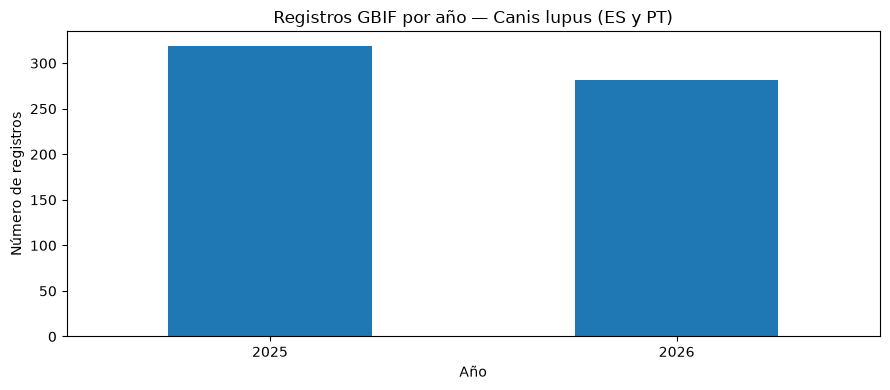

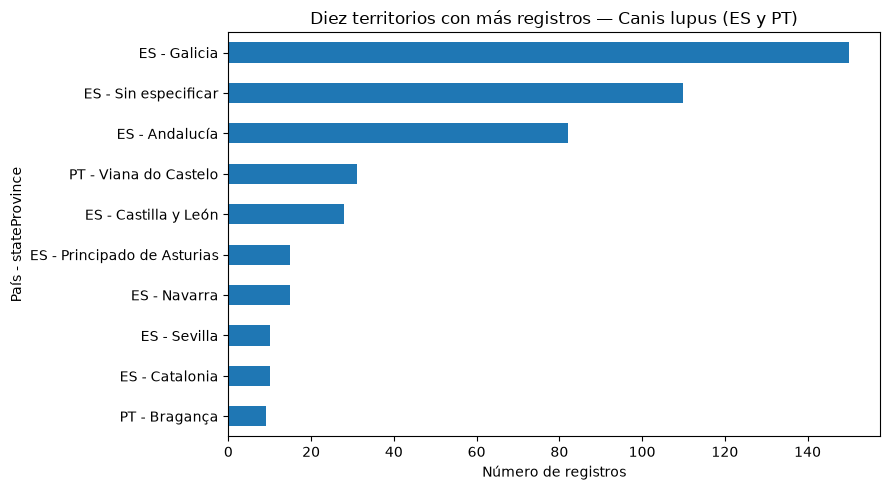

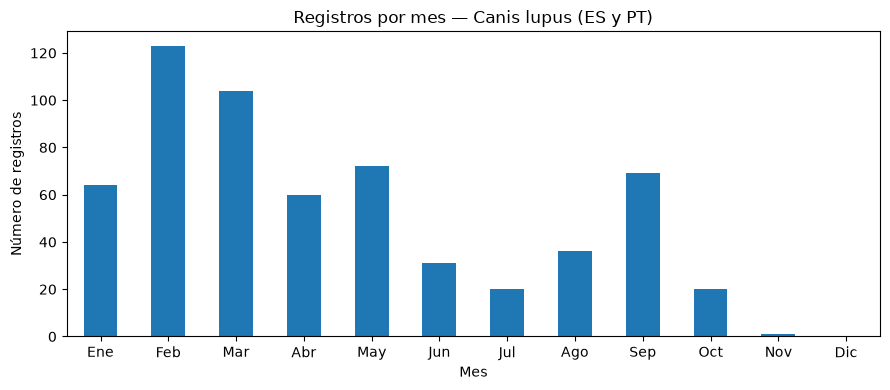

Conjunto limpio exportado a: registros_canis_lupus_es_pt.csv


In [29]:
if not df.empty:
    registros_por_anio = df.dropna(subset=["year"]).groupby("year").size().sort_index()
    if not registros_por_anio.empty:
        ax = registros_por_anio.plot(
            kind="bar", figsize=(9, 4),
            title=f"Registros GBIF por año — {ESPECIE_OBJETIVO} (ES y PT)"
        )
        ax.set_xlabel("Año")
        ax.set_ylabel("Número de registros")
        plt.xticks(rotation=0)
        plt.tight_layout()
        plt.show()

    territorio_pais = df["countryCode"].fillna("??") + " - " + df["stateProvince"].fillna("Sin especificar")
    top_territorios = territorio_pais.value_counts().head(10).sort_values()
    if not top_territorios.empty:
        ax = top_territorios.plot(
            kind="barh", figsize=(9, 5),
            title=f"Diez territorios con más registros — {ESPECIE_OBJETIVO} (ES y PT)"
        )
        ax.set_xlabel("Número de registros")
        ax.set_ylabel("País - stateProvince")
        plt.tight_layout()
        plt.show()

    registros_por_mes = df.dropna(subset=["month"]).groupby("month").size().reindex(range(1, 13), fill_value=0)
    if registros_por_mes.sum() > 0:
        ax = registros_por_mes.plot(
            kind="bar", figsize=(9, 4),
            title=f"Registros por mes — {ESPECIE_OBJETIVO} (ES y PT)"
        )
        ax.set_xlabel("Mes")
        ax.set_ylabel("Número de registros")
        plt.xticks(range(12), ["Ene", "Feb", "Mar", "Abr", "May", "Jun", "Jul", "Ago", "Sep", "Oct", "Nov", "Dic"], rotation=0)
        plt.tight_layout()
        plt.show()

    slug_especie = ESPECIE_OBJETIVO.lower().replace(" ", "_")
    ruta_csv = f"registros_{slug_especie}_es_pt.csv"
    df.to_csv(ruta_csv, index=False, encoding="utf-8-sig")
    print(f"Conjunto limpio exportado a: {ruta_csv}")
else:
    print("No se generan gráficos ni CSV porque no hay registros válidos.")

### Análisis Comparativo de `basisOfRecord` (España vs. Portugal)

A continuación, cruzamos la variable de país (`countryCode`) con el tipo de registro (`basisOfRecord`) para evaluar posibles diferencias en las fuentes de datos recopiladas en ambos territorios de la Península Ibérica.

=== Frecuencias Absolutas de basisOfRecord por País ===


countryCode,ES,PT,Total
basisOfRecord,,,
HUMAN_OBSERVATION,480,66,546
MACHINE_OBSERVATION,54,0,54
Total,534,66,600



=== Distribución Porcentual (%) de basisOfRecord dentro de cada País ===


countryCode,ES,PT
basisOfRecord,,
HUMAN_OBSERVATION,89.89,100.0
MACHINE_OBSERVATION,10.11,0.0


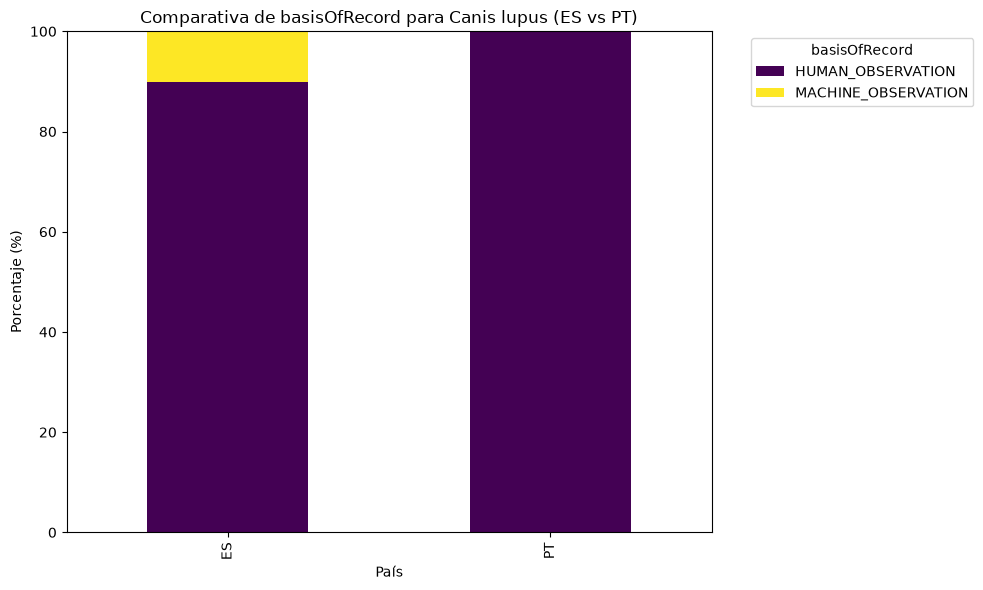

In [31]:
if not df.empty:
    # Crear una tabla de contingencia (frecuencias absolutas y porcentajes)
    tabla_contingencia = pd.crosstab(
        df['basisOfRecord'].fillna('Sin especificar'),
        df['countryCode'].fillna('Desconocido'),
        margins=True,
        margins_name='Total'
    )

    # Calcular porcentajes por columnas (por país) para comparar proporciones
    tabla_porcentajes = pd.crosstab(
        df['basisOfRecord'].fillna('Sin especificar'),
        df['countryCode'].fillna('Desconocido'),
        normalize='columns'
    ) * 100

    print("=== Frecuencias Absolutas de basisOfRecord por País ===")
    display(tabla_contingencia)

    print("\n=== Distribución Porcentual (%) de basisOfRecord dentro de cada País ===")
    display(tabla_porcentajes.round(2))

    # Generar un gráfico de barras apiladas o agrupadas si hay datos suficientes
    paises_presentes = [c for c in ['ES', 'PT'] if c in tabla_porcentajes.columns]
    if paises_presentes:
        ax = tabla_porcentajes[paises_presentes].T.plot(
            kind='bar',
            stacked=True,
            figsize=(10, 6),
            colormap='viridis'
        )
        plt.title(f"Comparativa de basisOfRecord para {ESPECIE_OBJETIVO} (ES vs PT)")
        plt.xlabel("País")
        plt.ylabel("Porcentaje (%)")
        plt.legend(title="basisOfRecord", bbox_to_anchor=(1.05, 1), loc='upper left')
        plt.tight_layout()
        plt.show()
else:
    print("No hay registros válidos en el DataFrame para realizar la comparación.")

### Estadísticas Descriptivas de las Coordenadas Geográficas

A continuación, calculamos métricas estadísticas clave (media, desviación estándar, mínimos, percentiles y máximos) para las coordenadas de latitud y longitud del conjunto de datos validado.

In [32]:
if 'df' in globals() and not df.empty:
    # Seleccionar únicamente las columnas de latitud y longitud
    estadisticas_coordenadas = df[['decimalLatitude', 'decimalLongitude']].describe()
    print("=== Estadísticas Descriptivas de Coordenadas ===")
    display(estadisticas_coordenadas)
else:
    print("El DataFrame 'df' no contiene datos válidos para calcular estadísticas.")

=== Estadísticas Descriptivas de Coordenadas ===


,decimalLatitude,decimalLongitude
count,600.000000,600.000000
mean,40.758928,-5.117506
std,2.507837,2.835754
min,28.364048,-16.465254
25%,37.880088,-7.522030
50%,42.044052,-5.480000
75%,42.482134,-3.110102
max,43.795468,2.817117


### Gráfico de Dispersión de Coordenadas (Latitud vs. Longitud)

Visualizamos la distribución espacial de los registros de presencia mapeando la longitud en el eje X y la latitud en el eje Y.

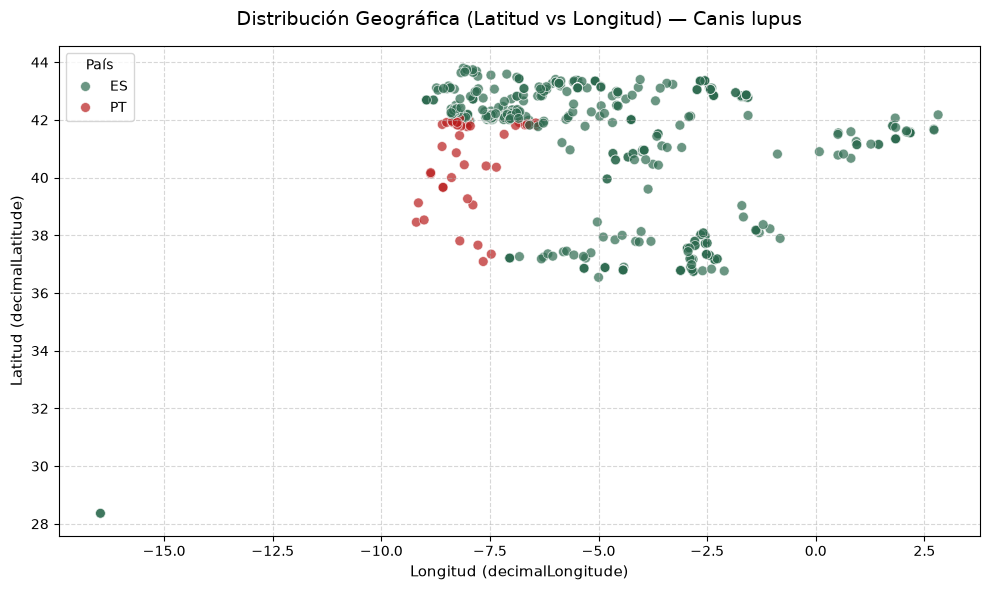

In [33]:
import matplotlib.pyplot as plt
import seaborn as sns

if 'df' in globals() and not df.empty:
    plt.figure(figsize=(10, 6))

    # Crear el gráfico de dispersión distinguiendo por país si está disponible
    sns.scatterplot(
        data=df,
        x='decimalLongitude',
        y='decimalLatitude',
        hue='countryCode' if 'countryCode' in df.columns else None,
        palette={'ES': '#2d6a4f', 'PT': '#b91c1c'} if 'countryCode' in df.columns else 'viridis',
        alpha=0.7,
        edgecolor='w',
        s=50
    )

    plt.title(f"Distribución Geográfica (Latitud vs Longitud) — {ESPECIE_OBJETIVO}", fontsize=14, pad=15)
    plt.xlabel("Longitud (decimalLongitude)", fontsize=11)
    plt.ylabel("Latitud (decimalLatitude)", fontsize=11)
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.legend(title="País")
    plt.tight_layout()
    plt.show()
else:
    print("El DataFrame 'df' no contiene datos válidos para graficar.")

## 6. Mapa interactivo de registros con Folium

El mapa incorpora agrupación de marcadores (`MarkerCluster`) y dos mapas base:

- **CartoDB Positron:** fondo claro para distinguir los puntos.
- **OpenTopoMap:** relieve topográfico.

Los popups muestran campos disponibles y un enlace a la ficha del registro en GBIF. Los textos procedentes de la API se escapan antes de insertarlos en HTML.

El encuadre se ajusta a la extensión de los puntos mediante `fit_bounds()`. Si no hay datos válidos, se muestra un mapa de referencia de España sin intentar calcular medias de un DataFrame vacío.

In [34]:
if df.empty:
    mapa = folium.Map(location=[40.0, -4.5], zoom_start=6, tiles="CartoDB positron")
    folium.LayerControl().add_to(mapa)
else:
    centro_lat = float(df["decimalLatitude"].median())
    centro_lon = float(df["decimalLongitude"].median())
    mapa = folium.Map(location=[centro_lat, centro_lon], zoom_start=6, tiles="CartoDB positron")

    folium.TileLayer(
        tiles="https://{s}.tile.opentopomap.org/{z}/{x}/{y}.png",
        attr="Map data: © OpenStreetMap contributors, SRTM | Map style: © OpenTopoMap (CC-BY-SA)",
        name="Relieve topográfico (OpenTopoMap)",
        overlay=False,
        control=True,
    ).add_to(mapa)

    cluster = MarkerCluster(name=f"Registros de {ESPECIE_OBJETIVO} (ES y PT)").add_to(mapa)

    for fila in df.itertuples(index=False):
        pais = html.escape(str(fila.countryCode)) if pd.notna(fila.countryCode) else "No especificado"
        fecha = html.escape(str(fila.eventDate)) if pd.notna(fila.eventDate) else "No disponible"
        territorio = html.escape(str(fila.stateProvince)) if pd.notna(fila.stateProvince) else "No especificado"
        altitud = fila.elevation
        altitud_txt = f"{altitud:.0f} m" if pd.notna(altitud) else "No disponible"
        institucion = html.escape(str(fila.institutionCode)) if pd.notna(fila.institutionCode) else "No especificada"
        gbif_id = html.escape(str(fila.key)) if pd.notna(fila.key) else ""
        tipo = html.escape(str(fila.basisOfRecord)) if pd.notna(fila.basisOfRecord) else "No especificado"

        popup_html = f"""
        <div style="font-family: sans-serif; font-size: 13px; min-width: 215px;">
            <b><i>{html.escape(nombre_oficial)}</i></b><hr style="margin: 4px 0;">
            <b>País:</b> {pais}<br>
            <b>Territorio:</b> {territorio}<br>
            <b>Fecha:</b> {fecha}<br>
            <b>Altitud:</b> {altitud_txt}<br>
            <b>Tipo de registro:</b> {tipo}<br>
            <b>Institución:</b> {institucion}<br>
            <a href="https://www.gbif.org/occurrence/{gbif_id}" target="_blank" rel="noopener noreferrer">Ver ficha en GBIF</a>
        </div>
        """

        color_borde = "#1b4332" if pais == "ES" else "#7f1d1d"
        color_relleno = "#2d6a4f" if pais == "ES" else "#b91c1c"

        folium.CircleMarker(
            location=[fila.decimalLatitude, fila.decimalLongitude],
            radius=5,
            color=color_borde,
            fill=True,
            fill_color=color_relleno,
            fill_opacity=0.85,
            popup=folium.Popup(popup_html, max_width=280),
            tooltip=f"[{pais}] {territorio} ({altitud_txt})",
        ).add_to(cluster)

    limites = [
        [float(df["decimalLatitude"].min()), float(df["decimalLongitude"].min())],
        [float(df["decimalLatitude"].max()), float(df["decimalLongitude"].max())],
    ]
    mapa.fit_bounds(limites)
    folium.LayerControl().add_to(mapa)

slug_especie = ESPECIE_OBJETIVO.lower().replace(" ", "_")
ruta_mapa = f"mapa_{slug_especie}_es_pt.html"
mapa.save(ruta_mapa)
print(f"Mapa guardado en: {ruta_mapa}")
mapa

c:\Users\chuwi\Documents\biodiversidad\.venv\Lib\site-packages\folium\raster_layers.py:129: UserWarning: CartoDB tiles now require an API key. Please provide one to continue using the tiles. You can request the key at https://carto.com/basemaps/apikey/.
  tiles = tiles.build_url(fill_subdomain=False, scale_factor="{r}")  # type: ignore


Mapa guardado en: mapa_canis_lupus_es_pt.html


### Guía e Interpretación del Mapa Interactivo

El mapa interactivo anterior utiliza una codificación de color visual para facilitar la comprensión de la procedencia y la densidad de los registros cargados en la Península Ibérica:

* **Puntos Individuales (Marcadores circulares):**
  * <span style="color:#2d6a4f; font-weight:bold;">Verde</span> (`#2d6a4f`): Representa observaciones georreferenciadas individuales registradas en **España** (`ES`).
  * <span style="color:#b91c1c; font-weight:bold;">Rojo</span> (`#b91c1c`): Representa observaciones georreferenciadas individuales registradas en **Portugal** (`PT`).

* **Agrupaciones (Marker Clusters):**
  * Cuando haces alejamiento (zoom out), los marcadores individuales muy cercanos se agrupan automáticamente para mantener limpio el mapa. Los círculos de agrupación cambian dinámicamente de color según el volumen de registros acumulados:
    * **Verde:** Baja densidad (menos de 10 registros agrupados).
    * **Amarillo:** Densidad media (decenas de registros agrupados).
    * **Naranja / Rojo:** Alta densidad (cientos de registros en la zona).

### Evaluación de la Integridad de la Muestra (`resumen_calidad`)

La fiabilidad del mapa depende de la calidad de las coordenadas. Consulta la tabla `resumen_calidad` de la sección 4 para conocer los campos ausentes en la muestra actual; sus valores varían según la consulta y no garantizan por sí solos la exactitud territorial ni taxonómica.

## 7. Lectura responsable de los resultados y posibles ampliaciones

- El recuento representa **registros** de GBIF, no individuos ni tamaño poblacional.
- `stateProvince` contiene el valor territorial suministrado por la fuente; no siempre equivale a una comunidad autónoma.
- `basisOfRecord` es una categoría Darwin Core, no una descripción completa del método de observación.
- El año 2026 no está completo; evita compararlo directamente con años completos.
- La altitud no se utiliza como filtro de descarga; las estadísticas de elevación se calculan sobre los registros que incluyen ese dato.
- La descarga está limitada por `MAX_REGISTROS`; consulta `total_disponible_gbif` para conocer el total que GBIF indica para esos filtros.

Como ampliaciones, se pueden comparar periodos equivalentes, permitir filtros configurables, añadir capas por año o tipo de registro y estudiar la incertidumbre espacial. Para inferir tendencias poblacionales harían falta datos y métodos específicos, no solo recuentos brutos de ocurrencias.